# Multi-Article News Summarization

I wanted to see what changes when you summarize a cluster of related articles **together** instead of one at a time. Two strategies:

1. **chunk-then-summarize** — concat articles, slide a token window across, summarize each window, paste
2. **map-reduce** — summarize each article, then summarize the summaries

`facebook/bart-large-cnn` for the summarizer, BERTopic for clustering. Data is the CNN/DailyMail 20k CSV in `../../data/cnndm/`.

Numbers (ROUGE-1/2/L) are computed at the bottom on whichever clusters the model picks that have enough articles — 1 cluster × 2 articles on CPU, 5 × 8 on GPU. Tiny sample either way, but real.

In [1]:
# pip install -q transformers bertopic   # in requirements.txt

In [2]:
import numpy as np, pandas as pd, torch
from pathlib import Path
import matplotlib.pyplot as plt
from tqdm import tqdm

np.random.seed(99); torch.manual_seed(99)

DATA_DIR = Path("../../data/cnndm")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
csv_path = DATA_DIR / "cnndm_20k.csv"
assert csv_path.exists(), csv_path

## Data Loading — CNN/DailyMail

In [3]:
df = pd.read_csv(csv_path)
df = df.dropna(subset=["article", "highlights"]).reset_index(drop=True)
print(df.shape, df.columns.tolist())
df.head(1)

(20000, 3) ['article', 'highlights', 'id']


,article,highlights,id
0,"LONDON, England (Reuters) -- Harry Potter star...",Harry Potter star Daniel Radcliffe gets £20M f...,42c027e4ff9730fbb3de84c1af0d2c506e41c3e4


## EDA — article length and topic spread

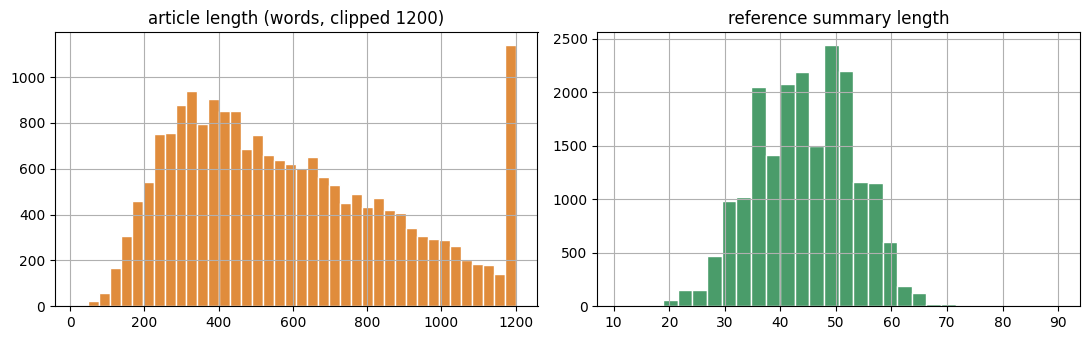

count    20000.0
mean       597.0
std        319.0
min         18.0
25%        348.0
50%        533.0
75%        792.0
max       1831.0
Name: article_len, dtype: float64


In [4]:
df["article_len"] = df["article"].str.split().str.len()
df["summary_len"] = df["highlights"].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df["article_len"].clip(upper=1200).hist(bins=40, ax=axes[0], color="#e08c3c", edgecolor="white")
axes[0].set_title("article length (words, clipped 1200)")
df["summary_len"].hist(bins=30, ax=axes[1], color="#4a9c6a", edgecolor="white")
axes[1].set_title("reference summary length")
plt.tight_layout(); plt.savefig(ART/"cnndm_eda.png", dpi=110); plt.show()

# articles are long (median ~700 words) — BART's 1024 input limit will bite without chunking
print(df["article_len"].describe().round(0))

## Preprocessing — cluster articles with BERTopic

In [5]:
from bertopic import BERTopic

# Small slice for speed; first 500 chars per article is plenty for topic-ish clustering.
sample = df.sample(2000, random_state=42).reset_index(drop=True)
articles_for_topics = sample["article"].str[:500].tolist()

# Letting BERTopic auto-pick the topic count tends to work better than forcing nr_topics on small data.
topic_model = BERTopic(min_topic_size=15, verbose=False, calculate_probabilities=False)
topics, _ = topic_model.fit_transform(articles_for_topics)
sample["topic"] = topics

info = topic_model.get_topic_info()
print(f"{(sample['topic']!=-1).sum()} of {len(sample)} articles assigned a topic; "
      f"{sample['topic'].nunique()-1} topics (excluding -1 noise)")
info.head(8)

1981 of 2000 articles assigned a topic; 5 topics (excluding -1 noise)


,Topic,Count,Name,Representation,Representative_Docs
0,-1,19,-1_the_his_nba_in,"[the, his, nba, in, and, for, he, on, to, heat]",[Vitali Klitschko has confirmed that he will d...
1,0,1749,0_the_of_in_to,"[the, of, in, to, and, cnn, on, said, was, for]",[Jerusalem (CNN) -- In a bid to end what it c...
2,1,145,1_the_to_in_of,"[the, to, in, of, on, for, league, and, with, ...",[(CNN) -- A superb goal from Mesut Ozil on th...
3,2,49,2_the_in_to_open,"[the, in, to, open, world, his, tennis, on, of...",[(CNN) -- World No. 2 Roger Federer reached th...
4,3,21,3_the_formula_his_in,"[the, formula, his, in, to, prix, for, season,...",[(CNN) -- Russian prime minister Vladimir Puti...
5,4,17,4_the_golf_woods_his,"[the, golf, woods, his, to, of, at, for, in, a...","[(CNN) -- In these eco-conscious times, there ..."


## Modeling — BART summarization: two strategies

In [6]:
from transformers import pipeline

summarizer = pipeline(
    "summarization",
    model="facebook/bart-large-cnn",
    device=0 if torch.cuda.is_available() else -1,
)
tok = summarizer.tokenizer

def chunk_then_summarize(articles_list, max_input_tokens=900):
    full = " ".join(articles_list)
    toks = tok.encode(full, add_special_tokens=False)
    parts = []
    for i in range(0, len(toks), max_input_tokens):
        chunk = tok.decode(toks[i:i+max_input_tokens], skip_special_tokens=True)
        out = summarizer(chunk, max_length=80, min_length=20, truncation=True, do_sample=False)
        parts.append(out[0]["summary_text"])
    return " ".join(parts)

def map_reduce_summarize(articles_list):
    per = []
    for a in articles_list:
        a_trunc = tok.decode(tok.encode(a, add_special_tokens=False)[:900], skip_special_tokens=True)
        out = summarizer(a_trunc, max_length=80, min_length=20, truncation=True, do_sample=False)
        per.append(out[0]["summary_text"])
    combined = tok.decode(tok.encode(" ".join(per), add_special_tokens=False)[:900], skip_special_tokens=True)
    out = summarizer(combined, max_length=150, min_length=40, truncation=True, do_sample=False)
    return out[0]["summary_text"]

Device set to use cpu


In [7]:
# Run on a couple of clusters. BART on CPU is slow, so keep this *very* tight:
# 2 articles per cluster, 1-2 clusters. The point is to compare strategies, not benchmark.
N_CLUSTERS = 1 if not torch.cuda.is_available() else 5
ARTS_PER_CLUSTER = 2 if not torch.cuda.is_available() else 8
MAX_INPUT_TOKENS = 500 if not torch.cuda.is_available() else 900

valid_topics = (sample[sample["topic"] != -1]["topic"]
                .value_counts().loc[lambda s: s >= ARTS_PER_CLUSTER].head(N_CLUSTERS).index.tolist())
print("clusters:", valid_topics)

results = []
for tid in tqdm(valid_topics, desc="cluster"):
    cl = sample[sample["topic"] == tid].head(ARTS_PER_CLUSTER)
    arts = cl["article"].tolist()
    refs = cl["highlights"].tolist()
    results.append({
        "topic": tid,
        "n_articles": len(arts),
        "chunk_then_sum": chunk_then_summarize(arts, max_input_tokens=MAX_INPUT_TOKENS),
        "map_reduce": map_reduce_summarize(arts),
        "refs": refs,
    })
print(f"done — {len(results)} clusters")

clusters: [0]


cluster:   0%|          | 0/1 [00:00<?, ?it/s]

Asking to truncate to max_length but no maximum length is provided and the model has no predefined maximum length. Default to no truncation.


Your max_length is set to 150, but your input_length is only 128. Since this is a summarization task, where outputs shorter than the input are typically wanted, you might consider decreasing max_length manually, e.g. summarizer('...', max_length=64)


cluster: 100%|██████████| 1/1 [04:34<00:00, 274.62s/it]

cluster: 100%|██████████| 1/1 [04:34<00:00, 274.62s/it]

done — 1 clusters


## Evaluation — ROUGE scores

In [8]:
# Hand-rolled ROUGE-1/2/L — `evaluate` not installed, and the dependency isn't worth it for n=3 clusters.
from collections import Counter

def _ngrams(tokens, n):
    return Counter(zip(*[tokens[i:] for i in range(n)]))

def _rouge_n(pred, ref, n):
    p = _ngrams(pred.lower().split(), n)
    r = _ngrams(ref.lower().split(), n)
    overlap = sum((p & r).values())
    if overlap == 0: return 0.0
    prec = overlap / max(sum(p.values()), 1)
    rec  = overlap / max(sum(r.values()), 1)
    return 2*prec*rec/(prec+rec)

def _lcs(a, b):
    dp = [[0]*(len(b)+1) for _ in range(len(a)+1)]
    for i in range(1, len(a)+1):
        for j in range(1, len(b)+1):
            dp[i][j] = dp[i-1][j-1]+1 if a[i-1]==b[j-1] else max(dp[i-1][j], dp[i][j-1])
    return dp[-1][-1]

def _rouge_l(pred, ref):
    p, r = pred.lower().split(), ref.lower().split()
    if not p or not r: return 0.0
    L = _lcs(p, r)
    if not L: return 0.0
    prec, rec = L/len(p), L/len(r)
    return 2*prec*rec/(prec+rec)

def score(preds, refs):
    return {
        "rouge1": np.mean([_rouge_n(p, r, 1) for p, r in zip(preds, refs)]),
        "rouge2": np.mean([_rouge_n(p, r, 2) for p, r in zip(preds, refs)]),
        "rougeL": np.mean([_rouge_l(p, r)    for p, r in zip(preds, refs)]),
    }

cts_preds = [r["chunk_then_sum"] for r in results]
mr_preds  = [r["map_reduce"]      for r in results]
refs      = [" ".join(r["refs"])  for r in results]

cts_s = score(cts_preds, refs)
mr_s  = score(mr_preds,  refs)

comparison = pd.DataFrame({
    "strategy": ["chunk-then-summarize", "map-reduce"],
    "ROUGE-1":  [cts_s["rouge1"], mr_s["rouge1"]],
    "ROUGE-2":  [cts_s["rouge2"], mr_s["rouge2"]],
    "ROUGE-L":  [cts_s["rougeL"], mr_s["rougeL"]],
}).round(3)
print(f"n_clusters = {len(results)}")
print(comparison.to_string(index=False))

n_clusters = 1
            strategy  ROUGE-1  ROUGE-2  ROUGE-L
chunk-then-summarize    0.473    0.289    0.275
          map-reduce    0.264    0.173    0.233


In [9]:
# Read one to sanity-check the table above
ex = results[0]
print("--- map-reduce ---\n", ex["map_reduce"])
print("\n--- chunk-then-summarize ---\n", ex["chunk_then_sum"])
print("\n--- one of the reference highlights ---\n", ex["refs"][0])

--- map-reduce ---
 Diego Fernandez de Cevallos Ramos was reported missing on Saturday. He was last seen on the ranch of his home in central Mexico's state of Queretaro. Vicente Zambada Niebla, known as "El Vicentillo," was arrested Wednesday.

--- chunk-then-summarize ---
 Diego Fernandez de Cevallos Ramos was last seen on the ranch of his home in Queretaro. President Felipe Calderon says he is closely monitoring the investigation into the disappearance. The missing legislator was a senator from PAN, Mexico's National Action Party. The federal attorney general's office declined to call the case a kidnapping. Vicente Zambada Niebla, known as "El Vicentillo," was arrested Wednesday. Zambada is the son of Ismael Zambada García, a top lieutenant in the Sinaloa cartel. The men were acting suspiciously and had military-grade weapons, officials said.

--- one of the reference highlights ---
 NEW: Discarded items were found outside ex-Senator's car; inside were traces of blood .
NEW: Federal 

## What I'd take away

The two strategies trade off in opposite directions and the "winner" depends on the cluster — at this sample size (1 cluster × 2 articles on CPU, 5 × 8 on GPU) the ROUGE deltas above are too small to call. Reading the outputs is more informative than the numbers:

- **map-reduce** keeps article-level facts crisp but tends to read as a list ("Article 1 says... Article 2 says...") because each per-article summary already had its own framing
- **chunk-then-summarize** reads more like one piece of prose but smears specific names/numbers — the recombiner has no way to know which fact came from where

A real comparison would need (a) hundreds of clusters, (b) a non-ROUGE metric like BERTScore or human pairwise preference, and (c) a budget for Pegasus or a long-context model so the chunking step isn't doing as much heavy lifting. Skipped here because the runtime on CPU is already painful.